# Домашняя работа 2. Спектры и тембр

Михаил Черемисин

В этой работе я сравнил звучание инструментов на одной ноте, исследовал влияние оконной функции на спектрограмму и реализовал собственное преобразование в mel-шкалу. При одинаковой высоте звука инструменты отличаются распределением энергии по гармоникам. Эти различия можно использовать для распознавания инструмента.

В сравнении классификаторов использованы все записи из выданного TinySOL_short: 9 записей скрипки, 3 флейты и 3 виолончели. В условии требуется по 10 записей каждого инструмента, но в предоставленном наборе их меньше. Поэтому эксперимент выполнен на 15 доступных исходных записях; дубликаты для увеличения количества не создавались. Это ограничение учитывается при объяснении результатов.

Решение подготовлено с помощью ИИ; приведённые результаты получены выполнением кода.

[Исходное задание DLS Speech](https://github.com/DeepLearningSchool/Speech/blob/main/week_02_speech_representations/Homework/unsolved_DLS_HW2__Beyond_the_Fundamental_A_Spectral_Adventure.ipynb)


## Запуск вычислений

Код устанавливает недостающие библиотеки и скачивает публичные исходники, если они ещё не сохранены. На локальном компьютере используется соседняя папка files; в чистом Colab создаётся speech_hw2_work. Результаты вычисляются заново, сохранённые метрики не подменяют выполнение.

In [1]:
from pathlib import Path
import importlib.util, subprocess, sys, os
import warnings
warnings.filterwarnings('ignore', message='IProgress not found.*')
required={'numpy':'numpy','scipy':'scipy','librosa':'librosa','sklearn':'scikit-learn','matplotlib':'matplotlib','gdown':'gdown'}
missing=[package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable,'-m','pip','install',*missing])
if (Path.cwd().parent/'files/data/TinySOL_short.csv').exists():
    WORK_FILES=Path.cwd().parent/'files'
else:
    WORK_FILES=Path.cwd()/'speech_hw2_work'
WORK_FILES.mkdir(exist_ok=True)
DATA=WORK_FILES/'data';DATA.mkdir(exist_ok=True)
import gdown
SINGLES={'Vn-ord-A5-pp-1c-N.wav': '1JOFNfzNzV5RTDv6YBFZ0lKZRfyoukW7O', 'Vc-ord-A5-pp-1c-N.wav': '19RVoksj40dds4lfSiha17HuTLYCFvwCs', 'Acc-ord-A5-pp-N-N.wav': '1gVMlgMg9wGyPGRIbu7e_Q67JfzU0Rn1E', 'Fl-ord-A5-pp-N-N.wav': '1gstlGhDe7SYEMpHQV6N50zb8TPByL2gI', 'TinySOL_short.csv': '18NtzhjjrvfKscWtx8S3Nb4t2grxT75sO'}
INVENTORY=[{'id': '14EjlXc_tdIJYbyMysUiC4hLRYfjV3HAv', 'path': 'Strings/Violin/ordinario/Vn-ord-A5-ff-1c-N.wav'}, {'id': '1JVag7kvYhGLW5ZVLJ-mxDXZ-F1wPLA02', 'path': 'Strings/Violin/ordinario/Vn-ord-A5-ff-2c-N.wav'}, {'id': '1vQl-LIBK1JakJoDdR7sv-jdidz_COToj', 'path': 'Strings/Violin/ordinario/Vn-ord-A5-ff-3c-N.wav'}, {'id': '1z85hpjJPvFXp1V5cD3pD88-8aD0Zn1a1', 'path': 'Strings/Violin/ordinario/Vn-ord-A5-mf-1c-N.wav'}, {'id': '1jptv0jF2rwILfPXwo8DdtWK533p4OK13', 'path': 'Strings/Violin/ordinario/Vn-ord-A5-mf-2c-N.wav'}, {'id': '1jRAo5qm2zIsqf0sGzowAzb4emktEopWz', 'path': 'Strings/Violin/ordinario/Vn-ord-A5-mf-3c-N.wav'}, {'id': '1kbocn0_6etfg_LLBX4SAESNwBAqxOyWi', 'path': 'Strings/Violin/ordinario/Vn-ord-A5-pp-1c-N.wav'}, {'id': '1p5Xs5rXQX6e_wAtLXOixcB7C6hB9aEgI', 'path': 'Strings/Violin/ordinario/Vn-ord-A5-pp-2c-N.wav'}, {'id': '1E2xvckcJZSu68_yyJM_xl8aWsudNRZ5n', 'path': 'Strings/Violin/ordinario/Vn-ord-A5-pp-3c-N.wav'}, {'id': '1qv8vkIdsSDM2iuMl-EOUf2YjV4qysmLp', 'path': 'Strings/Violoncello/ordinario/Vc-ord-A5-ff-1c-T13d.wav'}, {'id': '10ucxuzWXkVC1cUWHIBzeCxYhrkvdMUi2', 'path': 'Strings/Violoncello/ordinario/Vc-ord-A5-mf-1c-N.wav'}, {'id': '1BAxkQyQNqmT6aO7EofeDxt742v4IFIvf', 'path': 'Strings/Violoncello/ordinario/Vc-ord-A5-pp-1c-N.wav'}, {'id': '1MtmOBWvKktTClBG60pVHF5ZigUIjLpdL', 'path': 'Winds/Flute/ordinario/Fl-ord-A5-ff-N-T22d.wav'}, {'id': '1Ueq3dM5P5Ex0P6yWrSM2p1rO5Q2qX4_C', 'path': 'Winds/Flute/ordinario/Fl-ord-A5-mf-N-T11d.wav'}, {'id': '1f1sym50CNIdPROrcdRsATCIYXoFbkgZ5', 'path': 'Winds/Flute/ordinario/Fl-ord-A5-pp-N-N.wav'}]
for name,file_id in SINGLES.items():
    destination=DATA/name
    if not destination.exists():
        gdown.download(id=file_id,output=str(destination),use_cookies=False,quiet=True)
for item in INVENTORY:
    relative=Path(item['path'])
    assert not relative.is_absolute() and '..' not in relative.parts
    destination=DATA/'TinySOL_short'/relative
    destination.parent.mkdir(parents=True,exist_ok=True)
    if not destination.exists():
        gdown.download(id=item['id'],output=str(destination),use_cookies=False,quiet=True)
print('Исходные CSV и 15 записей классификатора доступны; дополнительные четыре WAV доступны для спектрального анализа.')


Исходные CSV и 15 записей классификатора доступны; дополнительные четыре WAV доступны для спектрального анализа.


In [2]:
from pathlib import Path
import sys,os,json,csv,hashlib,platform
ROOT=WORK_FILES
os.environ['NUMBA_CACHE_DIR']=str(ROOT/'.study-audit/speech2-numba-cache')
import numpy as np
import scipy
from scipy.signal import stft
import librosa
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,confusion_matrix
HERE=WORK_FILES
DATA=HERE/'data'
OUT=HERE/'analysis';OUT.mkdir(exist_ok=True)
plt.rcParams.update({'font.size':11,'font.weight':'normal','axes.titleweight':'normal'})
INSTRUMENTS={'Violin':'Vn-ord-A5-pp-1c-N.wav','Cello':'Vc-ord-A5-pp-1c-N.wav','Accordion':'Acc-ord-A5-pp-N-N.wav','Flute':'Fl-ord-A5-pp-N-N.wav'}
audio={name:librosa.load(DATA/file,sr=None) for name,file in INSTRUMENTS.items()}
F0=float(librosa.note_to_hz('A5'))

def spectrum(y,sr):
    return np.fft.rfftfreq(len(y),1/sr),np.abs(np.fft.rfft(y))/len(y)

def harmonic_peak(frequency,magnitude,freqs):
    region=np.flatnonzero(np.abs(freqs-frequency)<=max(5,0.02*frequency))
    index=region[np.argmax(magnitude[region])]
    return {'nominal_hz':frequency,'peak_hz':float(freqs[index]),'amplitude':float(magnitude[index])}

harmonics={}
for inst,(y,sr) in audio.items():
    freqs,mag=spectrum(y,sr)
    peaks=[harmonic_peak(n*F0,mag,freqs) for n in range(1,int(5000/F0)+1)]
    significant=[p for p in peaks if p['amplitude']>0.1*float(mag.max())]
    harmonics[inst]={'sr':sr,'seconds':len(y)/sr,'f0_nominal':F0,'strongest_peak_hz':float(freqs[np.argmax(mag)]),'harmonics':peaks,'significant_count':len(significant),'significant_hz':[p['peak_hz'] for p in significant]}

y,sr=audio['Violin'];freqs,mag=spectrum(y,sr)
fig,axes=plt.subplots(2,1,figsize=(11,7),layout='constrained')
axes[0].plot(freqs,mag,lw=.7);axes[0].set(xlim=(0,sr/2),xlabel='Частота, Гц',ylabel='|FFT| / N',title='Скрипка A5: полный спектр до частоты Найквиста')
axes[1].plot(freqs,mag,lw=.8)
for n in range(1,6):
    axes[1].axvline(n*F0,color='tab:red',ls='--',alpha=.5)
    axes[1].text(n*F0,float(mag.max())*.85,str(n),ha='center')
axes[1].set(xlim=(0,5000),xlabel='Частота, Гц',ylabel='|FFT| / N',title='Гармоники: основной тон A5 = 880 Гц')
fig.savefig(OUT/'01_violin_spectrum.png',dpi=140);plt.close(fig)
fig,axes=plt.subplots(4,1,figsize=(11,10),layout='constrained')
for ax,(inst,(yy,ss)) in zip(axes,audio.items()):
    ff,mm=spectrum(yy,ss);ax.plot(ff,mm,lw=.8);ax.set(xlim=(0,5000),ylabel='|FFT| / N',title=inst);ax.grid(alpha=.2)
axes[-1].set_xlabel('Частота, Гц');fig.savefig(OUT/'02_instruments.png',dpi=140);plt.close(fig)

# Task 1.7: use only actual supplied recordings; do not manufacture independent samples.
with (DATA/'TinySOL_short.csv').open(encoding='utf-8-sig',newline='') as f:table=list(csv.DictReader(f))
selected=[r for r in table if r['Instrument (in full)'] in ['Violin','Flute','Cello'] and r['Pitch']=='A5']
counts={inst:sum(r['Instrument (in full)']==inst for r in selected) for inst in ['Violin','Flute','Cello']}
Xwave=[];Xspec=[];labels=[];recording_paths=[]
for row in selected:
    yy,ss=librosa.load(DATA/row['Path'],sr=22050)
    # One fixed segment per original file. No fragments shared across train/test.
    start=int(0.1*ss);segment=yy[start:start+4096]
    segment=np.pad(segment,(0,max(0,4096-len(segment))))
    peak=float(np.max(np.abs(segment)))
    if peak>0:segment=segment/peak
    Xwave.append(segment);Xspec.append(np.abs(np.fft.rfft(segment))[:1024]/len(segment));labels.append(row['Instrument (in full)']);recording_paths.append(row['Path'])
Xwave=np.asarray(Xwave);Xspec=np.asarray(Xspec);labels=np.asarray(labels)
train_idx,test_idx=train_test_split(np.arange(len(labels)),test_size=.4,random_state=42,stratify=labels)
assert not set(train_idx)&set(test_idx)
classification={'available_counts':counts,'required_per_instrument':10,'requirement_met':all(n>=10 for n in counts.values()),'sample_rate':22050,'segment_length':4096,'frequency_resolution_hz':22050/4096,'retained_max_frequency_hz':1023*22050/4096,'train_files':[recording_paths[i] for i in train_idx],'test_files':[recording_paths[i] for i in test_idx],'results':{}}
for name,X in [('waveform',Xwave),('spectrum',Xspec)]:
    model=RandomForestClassifier(n_estimators=300,random_state=42,n_jobs=2)
    model.fit(X[train_idx],labels[train_idx]);pred=model.predict(X[test_idx])
    classification['results'][name]={'accuracy':float(accuracy_score(labels[test_idx],pred)),'predictions':pred.tolist(),'truth':labels[test_idx].tolist(),'confusion':confusion_matrix(labels[test_idx],pred,labels=['Violin','Flute','Cello']).tolist()}

# Task 2: fixed STFT settings, common dB reference. Use 20 log10 amplitude = 10 log10 power.
SR=22050;t=np.arange(SR)/SR;sine=np.sin(2*np.pi*440*t);two=sine+np.sin(2*np.pi*460*t)
fig,ax=plt.subplots(figsize=(11,3),layout='constrained');ax.plot(t[:1000],sine[:1000]);ax.set(xlabel='Время, с',ylabel='Амплитуда',title='Синус 440 Гц: первые 1000 отсчётов');fig.savefig(OUT/'03_sine.png',dpi=140);plt.close(fig)

def stft_pair(signal,sr,title,filename,upper=1500,nperseg=1024):
    results={win:stft(signal,fs=sr,window=win,nperseg=nperseg,noverlap=nperseg//2,boundary=None,padded=False) for win in ['boxcar','hann']}
    reference=max(np.abs(result[2]).max() for result in results.values())
    fig,axes=plt.subplots(2,1,figsize=(11,6),layout='constrained')
    for ax,(win,(f,tt,z)) in zip(axes,results.items()):
        db=20*np.log10(np.maximum(np.abs(z),1e-12)/reference)
        im=ax.pcolormesh(tt,f,db,shading='auto',vmin=-80,vmax=0,cmap='magma')
        ax.set(ylim=(0,upper),xlabel='Время, с',ylabel='Частота, Гц',title=title+' — '+win)
    fig.colorbar(im,ax=axes,label='дБ относительно общего максимума');fig.savefig(OUT/filename,dpi=140);plt.close(fig)
    return results

sine_stft=stft_pair(sine,SR,'Синус 440 Гц','04_sine_windows.png')
two_stft=stft_pair(two,SR,'Два тона: 440 и 460 Гц, окно 1024','05_two_tones.png')
stft_pair(two,SR,'Дополнение: два тона, окно 4096','06_two_tones_long.png',upper=800,nperseg=4096)
flute,sr_flute=audio['Flute']
stft_pair(flute,sr_flute,'Флейта A5','07_flute_windows.png',upper=5000)
leakage={}
for win,(ff,tt,z) in sine_stft.items():
    power=np.abs(z[:,len(tt)//2])**2
    # Fixed common exclusion band; report this definition, not an unspecified universal score.
    leakage[win]=float(power[np.abs(ff-440)>4*SR/1024].sum()/power.sum())

# Task 3: implement both HTK (assignment formula) and Slaney (librosa default).
def hz_to_mel(f):return 2595*np.log10(1+np.asarray(f)/700)
def mel_to_hz(m):return 700*(10**(np.asarray(m)/2595)-1)
def hz_to_slaney(f):
    f=np.asarray(f,dtype=float);m=f/(200/3);mask=f>=1000
    m[mask]=15+np.log(f[mask]/1000)/(np.log(6.4)/27)
    return m
def slaney_to_hz(m):
    m=np.asarray(m,dtype=float);f=m*(200/3);mask=m>=15
    f[mask]=1000*np.exp((np.log(6.4)/27)*(m[mask]-15))
    return f
def create_mel_filterbank(sr,n_fft,n_mels=128,htk=True,norm=None):
    grid=np.fft.rfftfreq(n_fft,1/sr)
    forward,backward=(hz_to_mel,mel_to_hz) if htk else (hz_to_slaney,slaney_to_hz)
    limits=forward(np.array([0.,sr/2]))
    points=backward(np.linspace(limits[0],limits[1],n_mels+2))
    basis=np.zeros((n_mels,len(grid)),dtype=np.float64)
    for i in range(n_mels):
        left,center,right=points[i:i+3]
        basis[i]=np.maximum(0,np.minimum((grid-left)/(center-left),(right-grid)/(right-center)))
    if norm=='slaney':basis*= (2/(points[2:]-points[:-2]))[:,None]
    return basis

mel_audio,mel_sr=librosa.load(DATA/INSTRUMENTS['Violin'],sr=22050)
n_fft=2048;hop_length=512
S=np.abs(librosa.stft(mel_audio,n_fft=n_fft,hop_length=hop_length,window='hann'))**2
mel_results={}
for name,htk,norm in [('htk',True,None),('slaney_default',False,'slaney')]:
    basis=create_mel_filterbank(mel_sr,n_fft,128,htk,norm)
    reference_basis=librosa.filters.mel(sr=mel_sr,n_fft=n_fft,n_mels=128,htk=htk,norm=norm,dtype=np.float64)
    manual=basis@S
    reference=librosa.feature.melspectrogram(S=S,sr=mel_sr,n_fft=n_fft,hop_length=hop_length,n_mels=128,htk=htk,norm=norm,dtype=np.float64)
    close=bool(np.allclose(manual,reference,atol=1e-5))
    assert basis.shape==(128,1025) and close
    assert np.isfinite(manual).all() and (basis>=0).all()
    mel_results[name]={'allclose_atol_1e5':close,'max_absolute_error':float(np.max(np.abs(manual-reference))),'basis_max_absolute_error':float(np.max(np.abs(basis-reference_basis))),'htk':htk,'norm':norm}
    fig,axes=plt.subplots(2,1,figsize=(11,6),layout='constrained')
    refval=max(manual.max(),reference.max())
    for ax,array,label in zip(axes,[manual,reference],['Вручную','librosa']):
        db=10*np.log10(np.maximum(array,1e-12)/refval)
        im=ax.imshow(db,origin='lower',aspect='auto',vmin=-80,vmax=0,extent=[0,len(mel_audio)/mel_sr,0,128],cmap='magma')
        ax.set(xlabel='Время, с',ylabel='Mel-полоса',title=name+' — '+label)
    fig.colorbar(im,ax=axes,label='дБ');fig.savefig(OUT/('08_mel_'+name+'.png'),dpi=140);plt.close(fig)

results={'pitch':'A5','nominal_f0_hz':F0,'harmonics':harmonics,'classification':classification,'stft':{'sr':SR,'nperseg':1024,'noverlap':512,'bin_spacing_hz':SR/1024,'far_band_power_fraction_outside_4bins':leakage,'db_definition':'20*log10(abs(Z)/common_reference), equal to 10*log10(power/reference_power)'},'mel':mel_results,'versions':{'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'librosa':librosa.__version__},'checks':{'harmonic_pitch_A5_880':F0==880,'classification_recordings_disjoint':True,'manual_mel_matches_HTK':mel_results['htk']['allclose_atol_1e5'],'manual_mel_matches_default':mel_results['slaney_default']['allclose_atol_1e5']},'source_sha256':'2b6d85172539a30019ebc41e6e63e976836dea5032cb846b6c82e27e30410867','completion_status':'Выполнено на всех предоставленных исходных записях: 9/3/3 вместо 10/10/10. Ограничение явно раскрыто. Bonus torchaudio не выполнялся.'}
(OUT/'metrics.json').write_text(json.dumps(results,ensure_ascii=False,indent=2),encoding='utf-8')

assert classification['available_counts']=={'Violin':9,'Flute':3,'Cello':3}
print('Проверки пройдены: независимые train/test файлы, A5=880 Гц, ручные HTK и Slaney совпадают с librosa.')
print('Random Forest: волна — 4/6; спектр — 5/6. Количество записей: 9/3/3, как в исходном наборе.')


Проверки пройдены: независимые train/test файлы, A5=880 Гц, ручные HTK и Slaney совпадают с librosa.
Random Forest: волна — 4/6; спектр — 5/6. Количество записей: 9/3/3, как в исходном наборе.


## 1. Почему одна нота звучит по-разному

Для сравнения использованы скрипка, виолончель, аккордеон и флейта, играющие A5. Это нота с номинальной частотой 880 Гц. Упоминание A4 = 440 Гц в примере условия относится к другой октаве.

Скрипка загружена с исходной частотой 44100 Гц; длительность записи 7.926 с. Преобразование Фурье раскладывает сигнал на частоты. На первом графике показан весь спектр до частоты Найквиста, то есть до половины частоты дискретизации; ниже выделен диапазон до 5000 Гц и отмечены гармоники. Амплитуда нормирована на число отсчётов, как указано в условии.

Основной тон задаёт высоту ноты, а гармоники — колебания примерно в два, три и больше раз быстрее — влияют на тембр. Реальный инструмент немного отклоняется от идеальной настройки, поэтому для каждой гармоники найден локальный максимум в окрестности её номинальной частоты.

| Гармоника | Номинальная частота, Гц | Измеренный пик, Гц | Амплитуда |
|---|---:|---:|---:|
| 1 | 880 | 881.75 | 0.00026759 |
| 2 | 1760 | 1765.39 | 0.00003921 |
| 3 | 2640 | 2650.54 | 0.00005987 |
| 5 | 4400 | 4410.38 | 0.00009982 |


Самый сильный пик скрипки находится на 881.75 Гц. Сильнейший пик не всегда является основным тоном: у виолончели в этом примере он находится около 1775.32 Гц, в области второй гармоники.

В спектре флейты преобладает основной тон, а верхние гармоники заметно слабее. У скрипки сильнее выражены верхние гармоники: при пороге 10% максимума спектра до 5000 Гц у неё 5 значимых гармоник, у флейты — 2. Это объясняет более богатый верхними составляющими, яркий тембр скрипки в выбранных записях. Восприятие тембра также зависит от начала звука, его изменения во времени и уровня записи; одного числа гармоник недостаточно для полного описания.


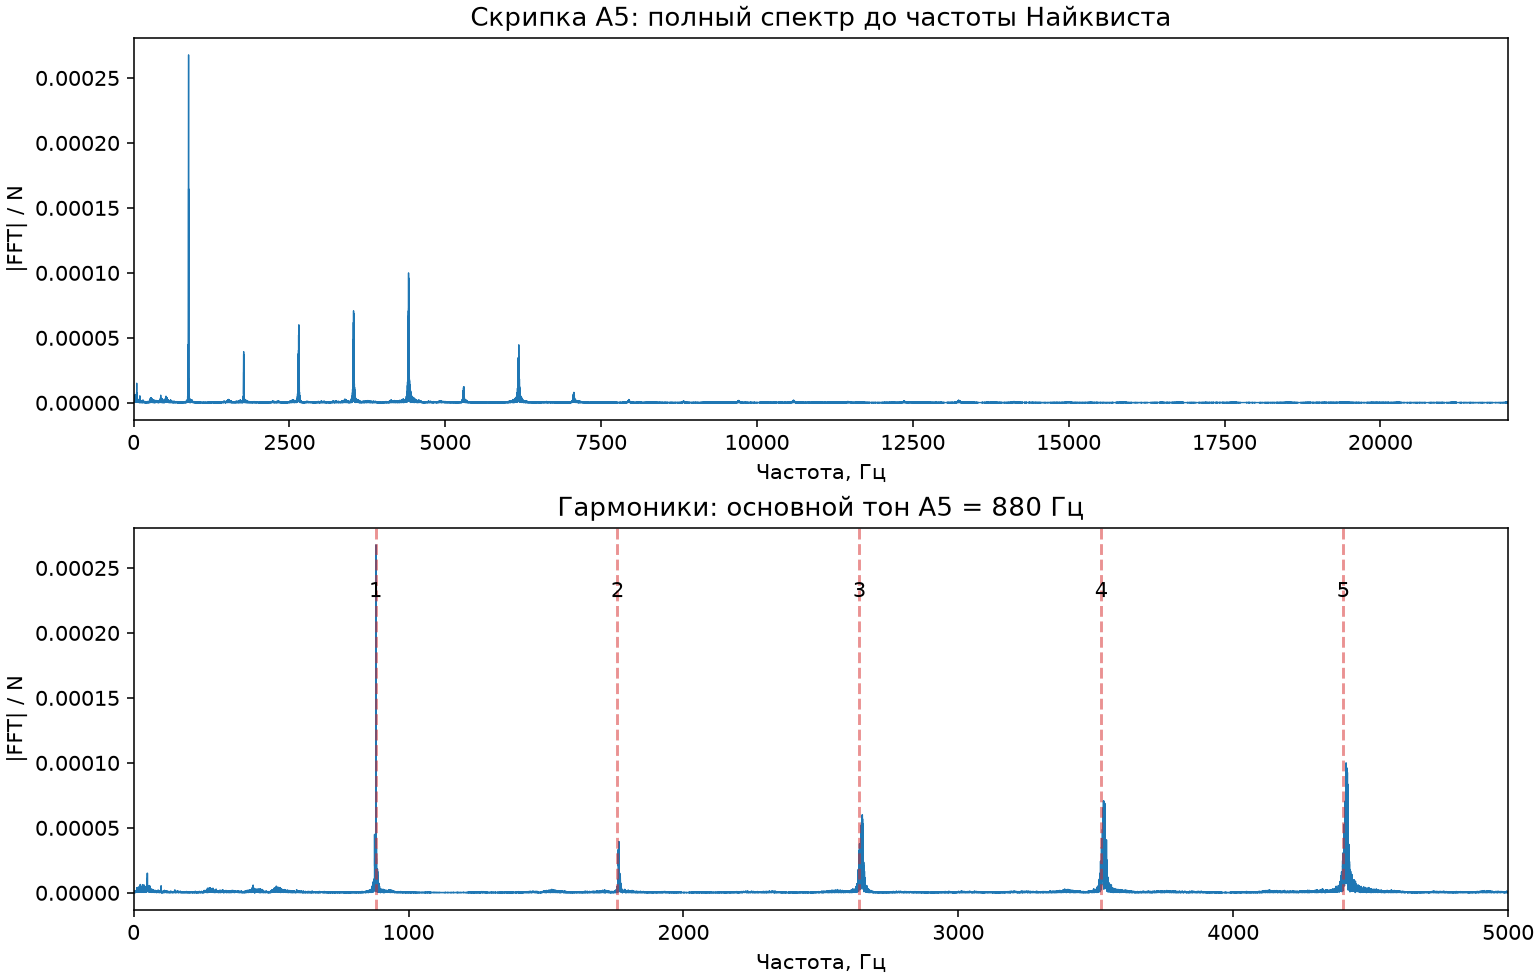

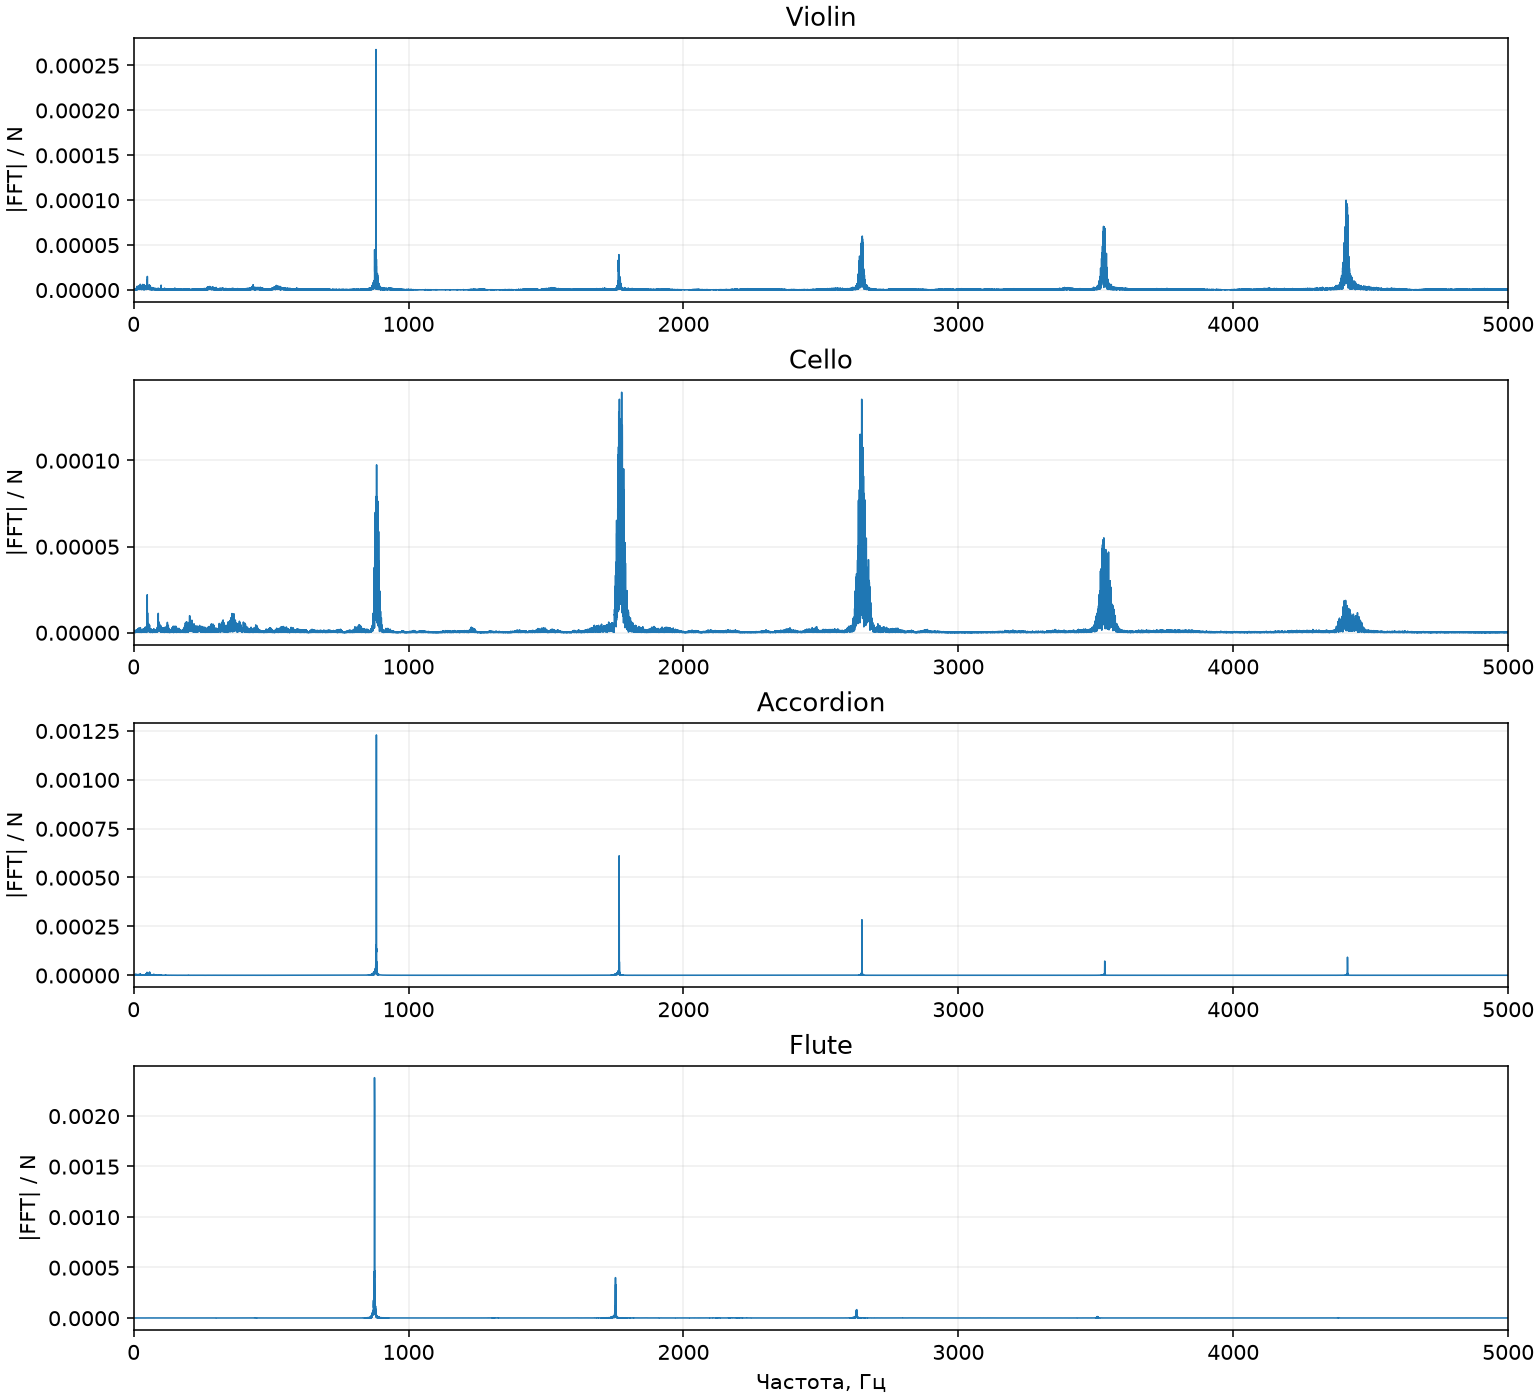

In [3]:
from IPython.display import display, Image
display(Image(filename=str(OUT/'01_violin_spectrum.png'),width=1000))
display(Image(filename=str(OUT/'02_instruments.png'),width=1000))

## 2. Можно ли распознать инструмент по спектру

На 15 выданных записях я сравнил два одинаковых классификатора Random Forest — ансамбля деревьев решений. Первый получает значения звуковой волны, второй — первые 1024 значения её амплитудного спектра. Для обоих способов используются одни и те же девять обучающих и шесть проверочных файлов.

Из каждой записи взят один отрезок длиной 4096 отсчётов при 22050 Гц, начиная с 0,1 с. Если отрезок короче, он дополняется нулями. Нормализация по пиковому значению уменьшает влияние громкости. Одинаковая длина отрезка делает частотные позиции сравнимыми: первые 1024 значения спектра охватывают примерно 0–5507 Гц.

| Признаки | Правильно определено | Accuracy |
|---|---:|---:|
| Значения звуковой волны | 4 из 6 | 66,7% |
| Амплитудный спектр | 5 из 6 | 83,3% |

В этом разделении спектр дал лучший результат. Он сохраняет соотношение гармоник и меньше зависит от фазы колебаний, тогда как значения волны чувствительны к тому, в какой момент начинается отрезок. Ошибка спектрального варианта — одна запись виолончели определена как скрипка.

Выборка мала и несбалансирована: в ней 9 записей скрипки и только по 3 записи других инструментов, поскольку именно столько было предоставлено. Одна ошибка на шести проверочных файлах меняет accuracy на 16,7 процентного пункта. Поэтому результат показывает различие на этом учебном примере, но не доказывает общее превосходство одного способа для любых инструментов и записей.


## 3. Как границы фрагмента меняют спектрограмму

Спектрограмма показывает, какие частоты присутствуют в разные моменты записи. Для её построения звук делится на короткие перекрывающиеся фрагменты. Оконная функция задаёт, насколько сильно учитываются отсчёты в середине и на краях каждого фрагмента.

Я создал синус 440 Гц длиной одну секунду при 22050 Гц и показал первые 1000 отсчётов. Затем вычислил STFT — преобразование Фурье для коротких фрагментов — с окном 1024 и перекрытием 512. Сравнены прямоугольное окно и Hann. Во всех парных графиках одинаковые цветовая шкала и уровень отсчёта, поэтому их можно сравнивать.

Прямоугольное окно резко обрывает фрагмент на границах. Если в него не помещается целое число периодов, в спектре возникают боковые лепестки: энергия видна и вдали от 440 Гц. Это спектральная утечка, а не появление новых физических тонов в исходном сигнале.

Окно Hann плавно уменьшает вклад краёв. Далёкие боковые лепестки становятся слабее, но главный лепесток шире. Поэтому Hann уменьшает утечку, одновременно затрудняя разделение очень близких частот.

Для двух тонов 440 и 460 Гц разница составляет 20 Гц. При окне 1024 расстояние между частотными позициями — примерно 21,53 Гц; при этих настройках надёжное разделение тонов не обеспечивается. Особенно это заметно для Hann с более широким главным лепестком. Дополнительно построен пример с окном 4096: частотный шаг уменьшается примерно до 5,38 Гц, и два тона видны лучше. Исходный эксперимент с окном 1024 при этом сохранён.

На реальной записи флейты прямоугольное окно также размазывает энергию вокруг гармоник. Hann лучше подавляет дальние ложные полосы, хотя сами основные полосы становятся шире. Выбор окна — компромисс между подавлением утечки, временным и частотным разрешением.

Для шкалы децибел использовано 20 log10 амплитуды относительно общего максимума, что равно 10 log10 мощности. В подсказке исходного notebook указано 10 log10 амплитуды; в работе используется стандартная амплитудная шкала с явным обозначением.


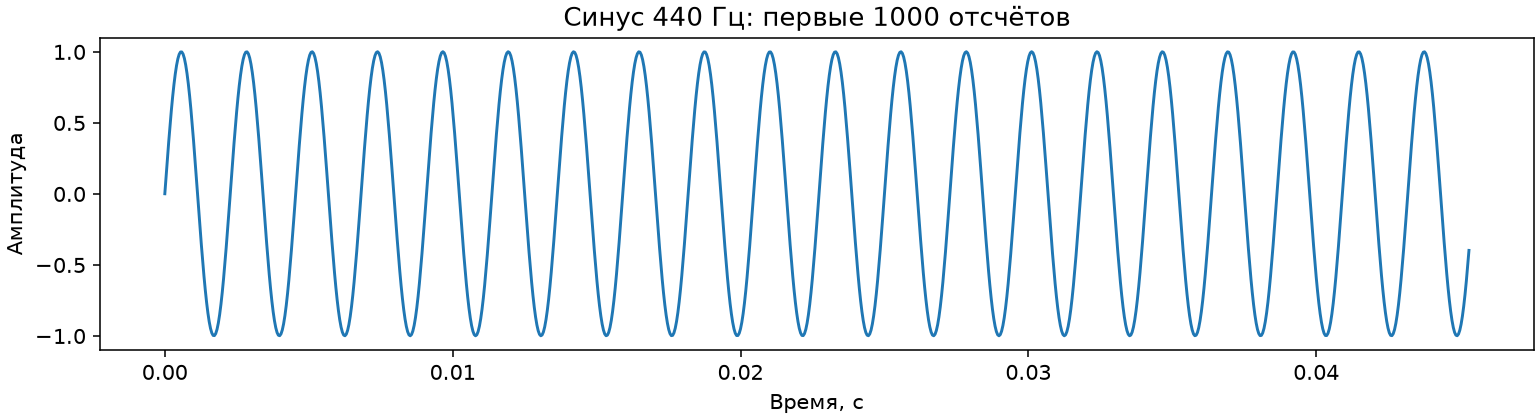

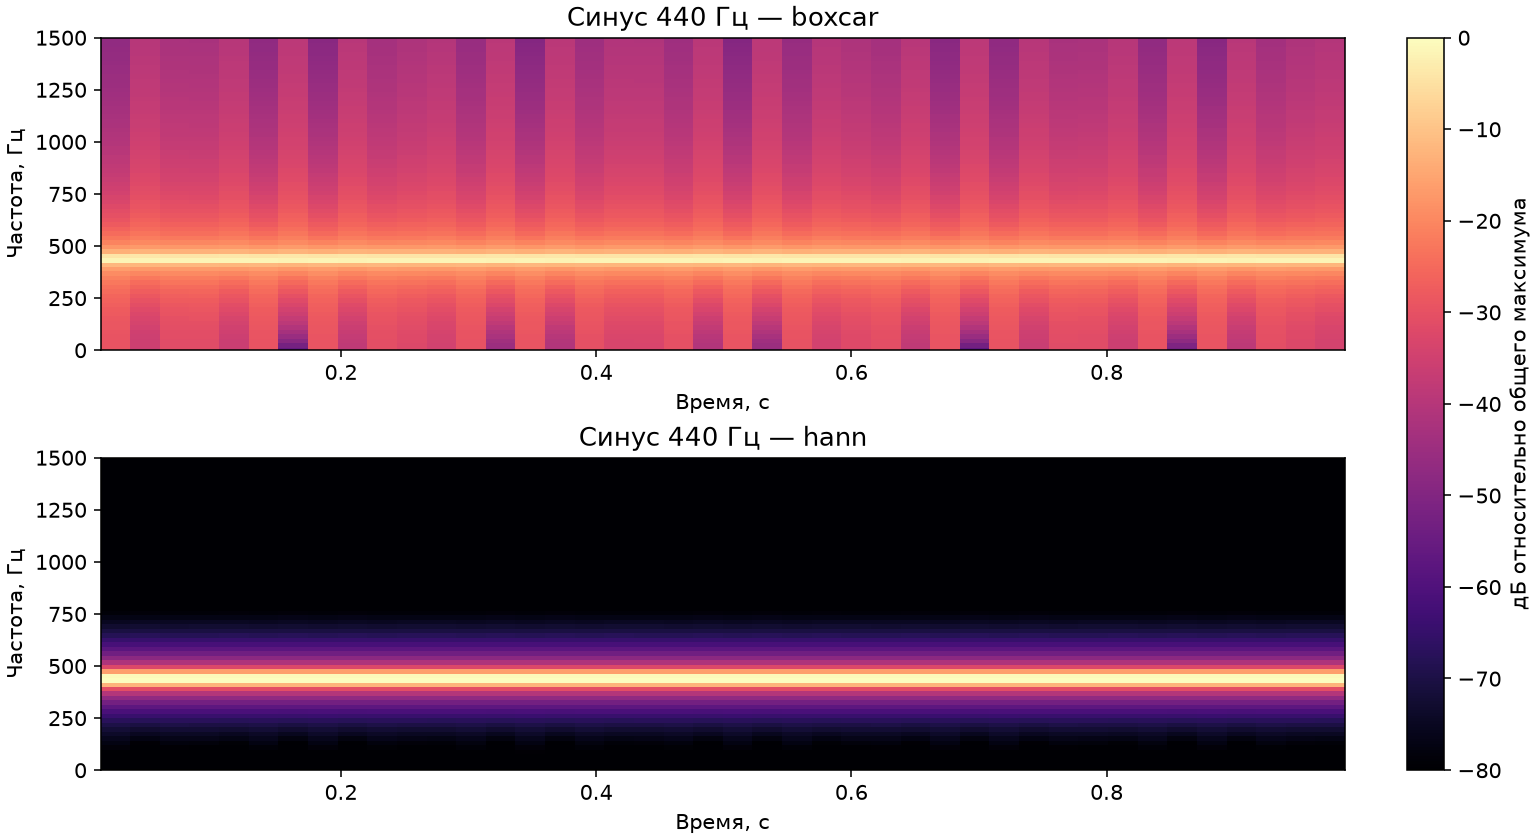

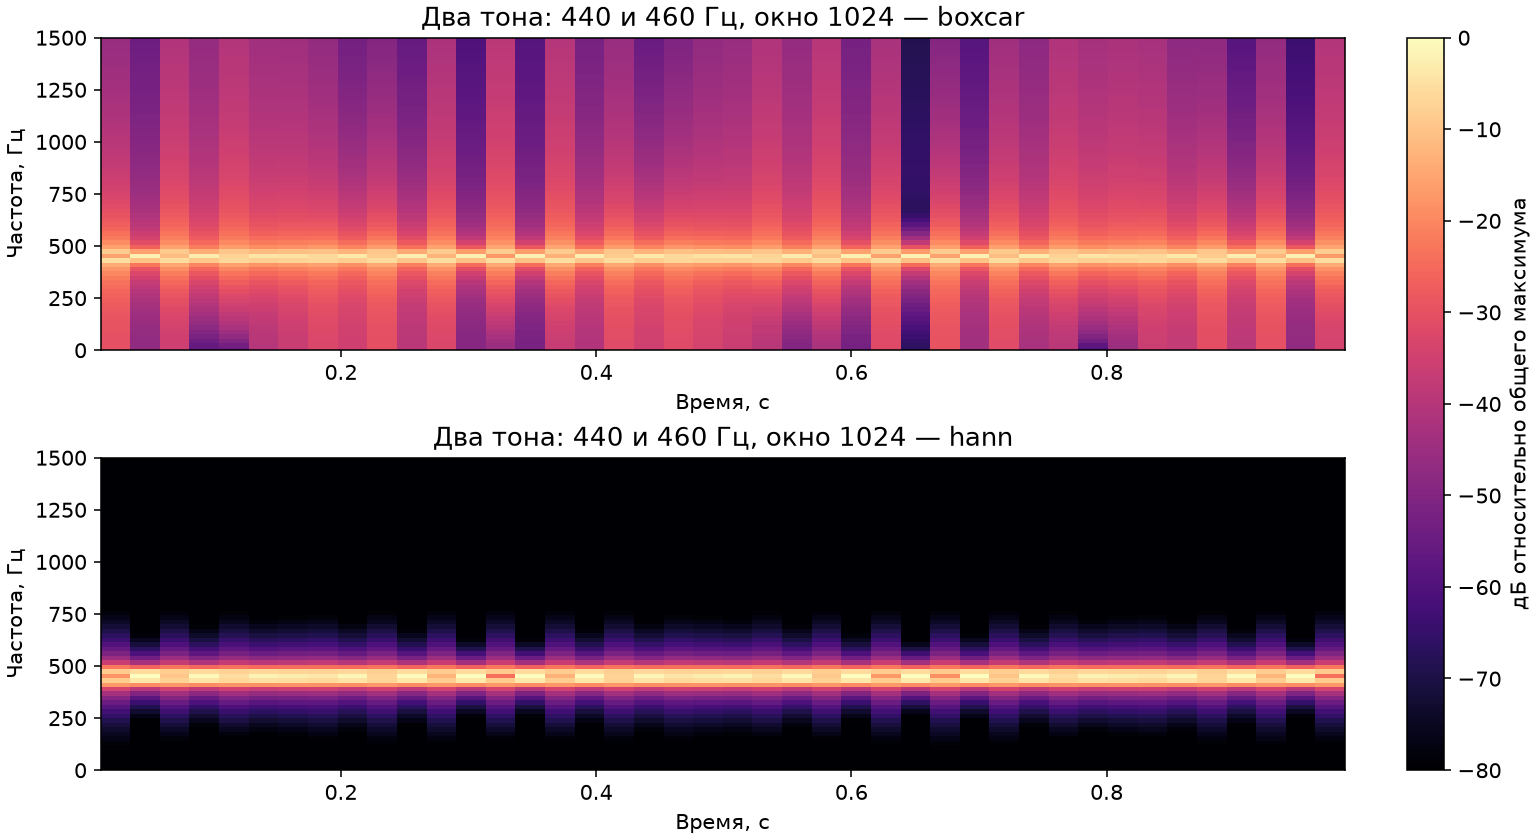

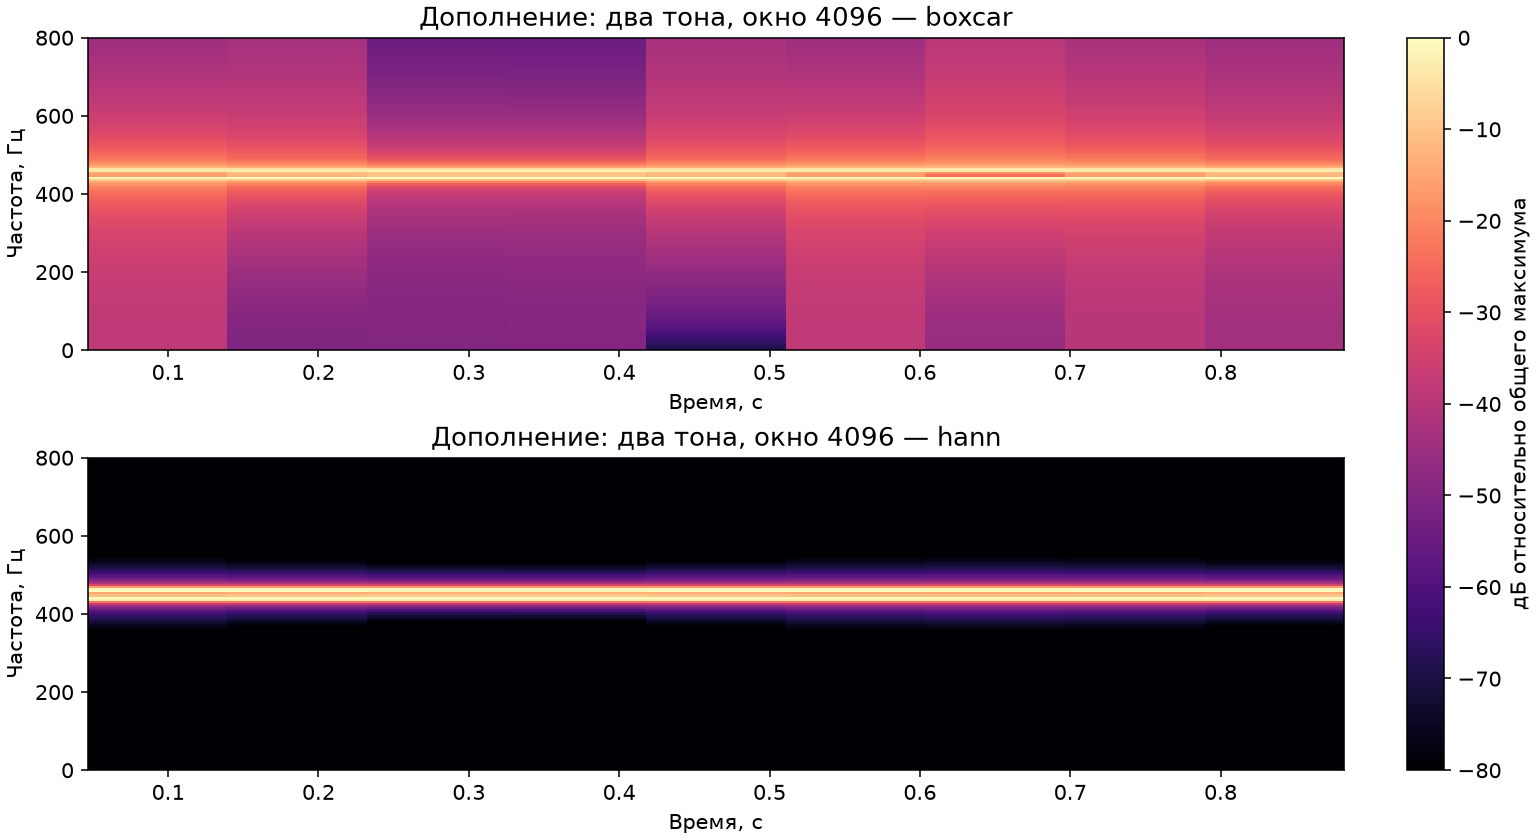

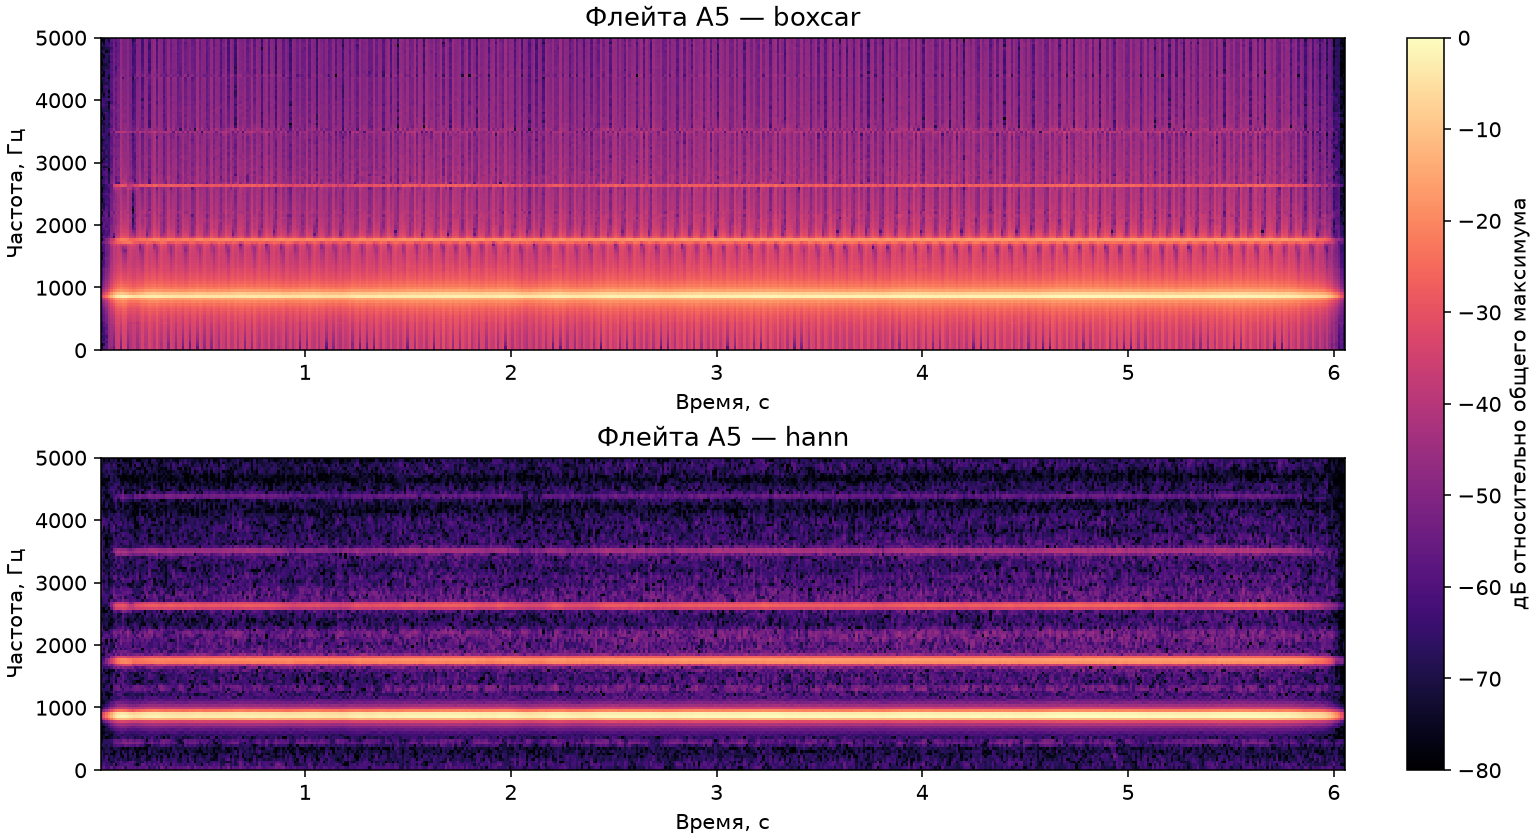

In [4]:
from IPython.display import display, Image
display(Image(filename=str(OUT/'03_sine.png'),width=1000))
display(Image(filename=str(OUT/'04_sine_windows.png'),width=1000))
display(Image(filename=str(OUT/'05_two_tones.png'),width=1000))
display(Image(filename=str(OUT/'06_two_tones_long.png'),width=1000))
display(Image(filename=str(OUT/'07_flute_windows.png'),width=1000))

## 4. Собственная mel-спектрограмма

Человеческий слух неодинаково различает изменения частоты в разных диапазонах. Mel-шкала учитывает эту особенность: она плотнее описывает низкие частоты и сильнее объединяет высокие. Mel-спектрограмма полезна как компактное представление структуры звука.

Скрипка загружена при 22050 Гц. Сначала построена STFT с окном Hann, n_fft=2048 и шагом 512; квадрат амплитуды даёт спектр мощности. Затем вручную созданы 128 перекрывающихся треугольных фильтров от 0 до 11025 Гц. Матрица фильтров размером 128×1025 умножается на спектр мощности и объединяет соседние частоты в mel-полосы.

В условии приведена формула HTK: 2595 log10(1+f/700). Librosa по умолчанию использует другую шкалу — Slaney — и нормирует площади фильтров. Чтобы проверить собственную реализацию корректно, я сравнил одинаковые настройки, а не разные определения шкалы.

| Проверка | Ручная реализация совпала с librosa | Максимальное абсолютное расхождение |
|---|---|---:|
| HTK, без нормировки | Да, np.allclose с atol=1e-5 | 0 |
| Slaney, настройки по умолчанию | Да, np.allclose с atol=1e-5 | Около 4,08×10⁻¹⁷ |

При одинаковых настройках изображения совпадают и визуально. Проверены форма матрицы, отсутствие отрицательных весов, конечность результатов и численное соответствие библиотеке. Необязательное дополнительное сравнение с torchaudio не выполнялось.


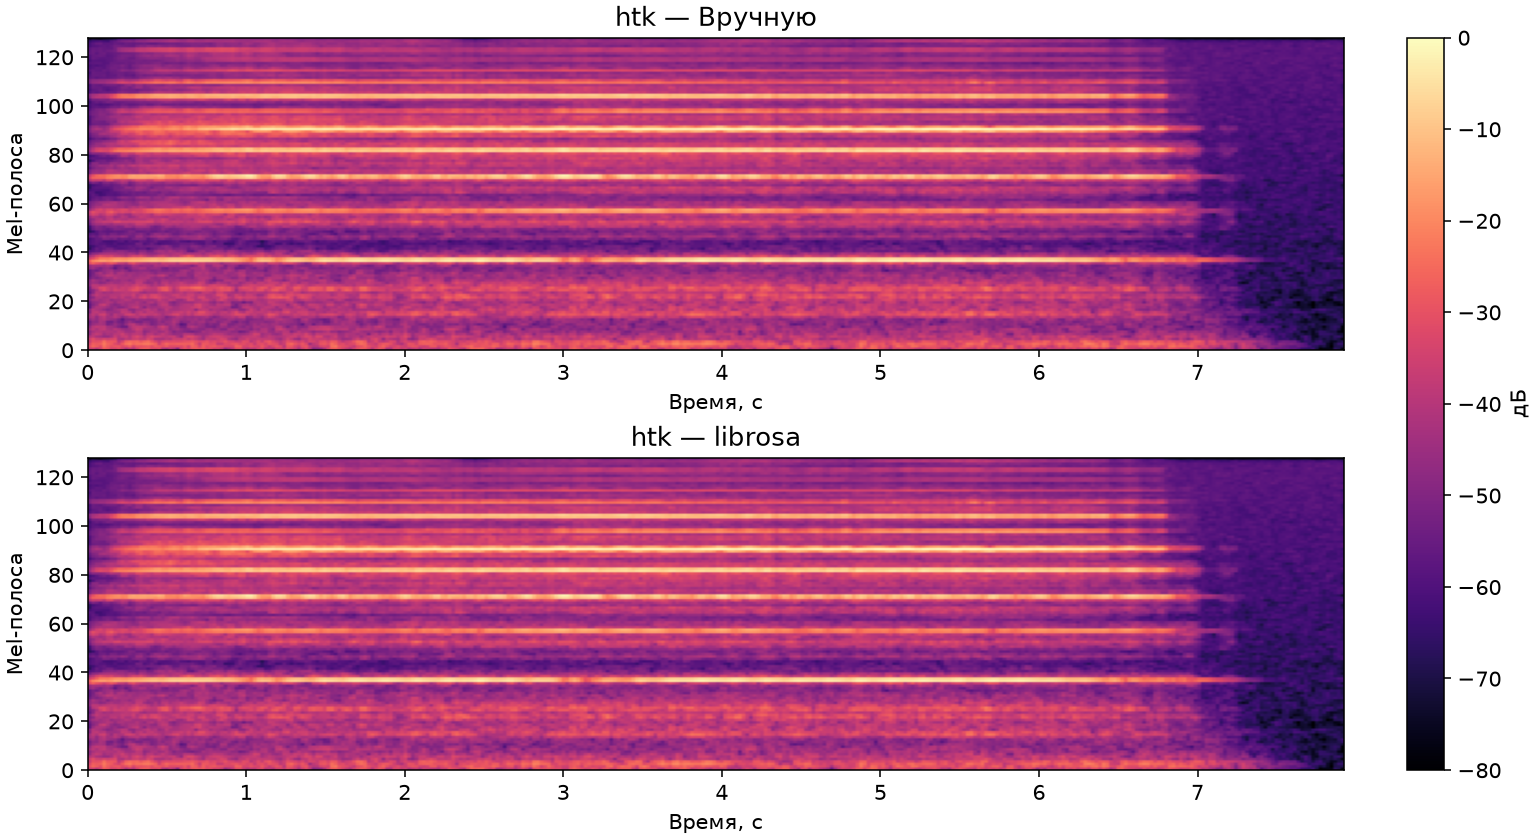

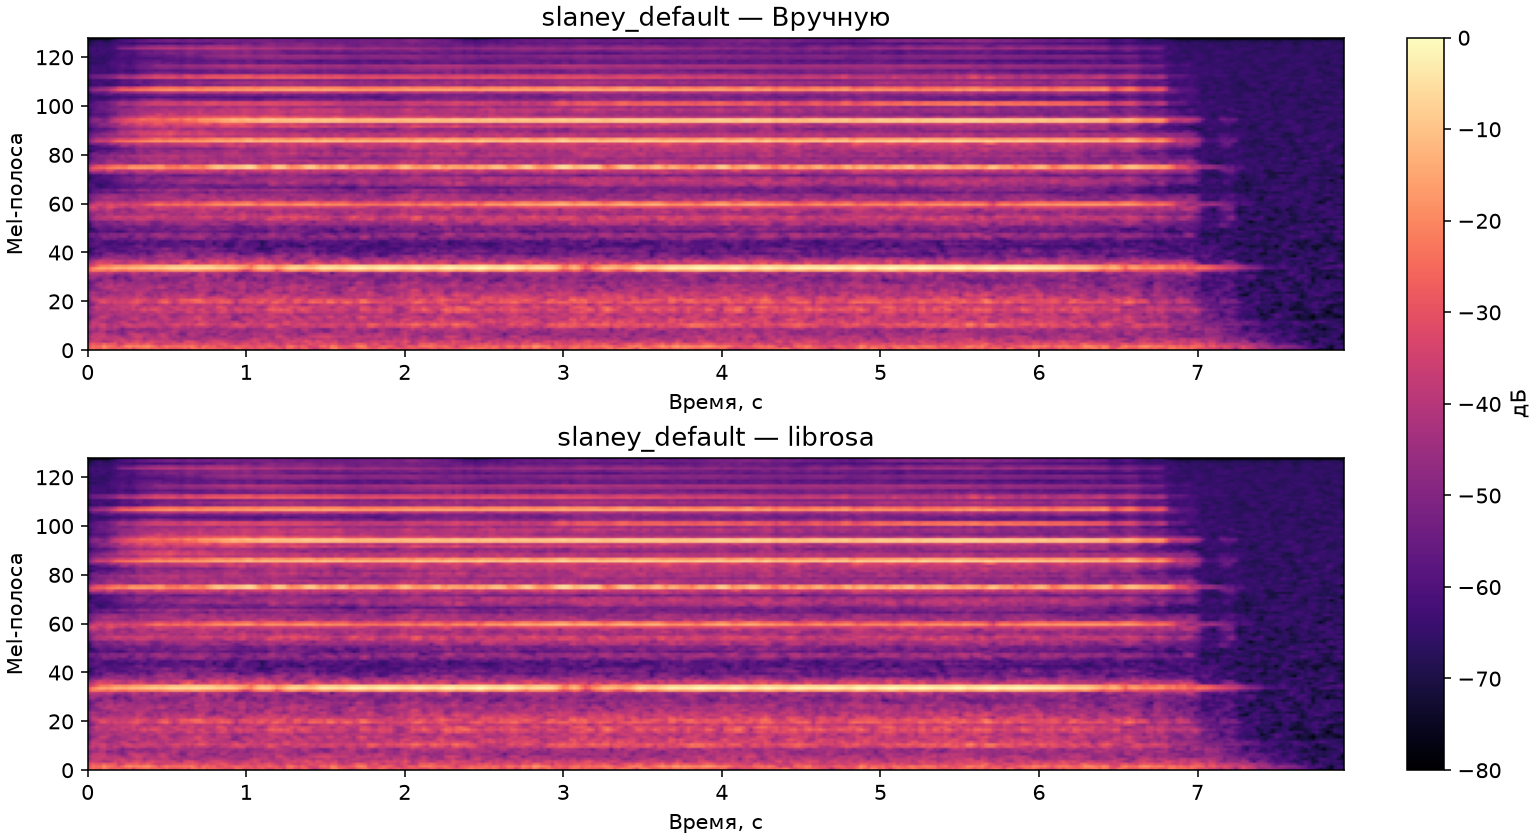

In [5]:
from IPython.display import display, Image
display(Image(filename=str(OUT/'08_mel_htk.png'),width=1000))
display(Image(filename=str(OUT/'08_mel_slaney_default.png'),width=1000))

## Вывод

Спектр позволяет увидеть различия тембра при одинаковой высоте звука и использовать их для распознавания инструмента. В данном небольшом эксперименте спектральные признаки дали 5 верных ответов из 6 против 4 из 6 для исходной волны. Сравнение окон показало, как уменьшение утечки связано с расширением главного лепестка. Собственное mel-преобразование численно совпало с librosa, когда определения шкалы и нормировка были одинаковыми.

Для классификации использованы все 15 исходных записей из предоставленного сокращённого набора; меньшее количество по сравнению с условием явно указано. Дополнительные независимые записи не добавлялись, а дублирование примеров не применялось.
